# 03 — Falsification, interpretability and figures

The experiments here are the ones that could show ZoomMoE does nothing.
Run them before writing anything up.

| test | what a null result means |
|---|---|
| 1. magnification-order permutation | PZR is not modelling zoom; the ordering premise is dead |
| 2. patient-identity probe | the embedding encodes slide/stain, not pathology |
| 3. expert usage vs magnification | the MoE conditioning is inert |
| 4. zoom-gain curve | higher magnifications add nothing; 40x suffices |
| 5. random-label control | the folds leak |

It also produces the figures for the report: the t-SNE pair, the ordinal zoom
trajectory, the expert heatmap, and the early-exit trade-off curve.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

for _p in ["/kaggle/input/datasets/nabinkoirala452/code-files", "/kaggle/working"]:
    if (Path(_p) / "breakhis_common.py").exists() and _p not in sys.path:
        sys.path.insert(0, _p)

import breakhis_common as bc
import zoommoe_model as zm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
OUT = Path("/kaggle/input/datasets/nabinkoirala452/articafts/artifacts")
FIG = Path("/kaggle/working")
bc.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
print("device:", DEVICE)


device: cuda


In [2]:
samples = pd.read_pickle(OUT / "samples_pool.pkl")
folds = list(np.load(OUT / "folds_all.npy", allow_pickle=True))

FOLD = 0
ckpt = torch.load("/kaggle/input/datasets/nabinkoirala452/notebook2-articafts-breakhis/artifacts/zoommoe_fold0.pt", map_location=DEVICE, weights_only=False)
cfg = ckpt["cfg"]
model = zm.ZoomMoE(cfg).to(DEVICE)
model.load_state_dict(ckpt["state_dict"])
model.eval()

from torch.utils.data import DataLoader

test_idx = folds[FOLD]["test"]
test_loader = DataLoader(
    bc.make_image_dataset(samples.iloc[test_idx], train=False, img_size=cfg.img_size),
    batch_size=8, shuffle=False, num_workers=2,
)
print(f"fold {FOLD}: {len(test_idx)} test samples, "
      f"{samples.iloc[test_idx].patient_id.nunique()} patients")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 208MB/s]


fold 0: 461 test samples, 16 patients


In [3]:
res = zm.collect(model, test_loader, DEVICE)
base_metrics = bc.evaluate(res["label"], res["prob"], res["patient_idx"])
print("ordered inference:", {k: round(v, 4) for k, v in base_metrics.items()})

ordered inference: {'acc': 0.9197, 'f1_macro': 0.8892, 'prr': 0.9174, 'auc': 0.9811}


## Test 1 — magnification-order permutation

Feed the four magnifications in a random order at test time. A model that
genuinely treats zoom as a directed refinement process should degrade. A
permutation-invariant model (the baseline) should not move at all.

The number that matters is the **gap**, not the absolute score.

In [4]:
def permutation_sweep(model, loader, n_perm=6, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = [{"order": "0,1,2,3", "kind": "ordered",
             **bc.evaluate(res["label"], res["prob"], res["patient_idx"])}]
    seen = {(0, 1, 2, 3)}
    for _ in range(n_perm):
        order = tuple(rng.permutation(4).tolist())
        if order in seen:
            continue
        seen.add(order)
        r = zm.collect(model, loader, DEVICE, order=list(order))
        rows.append({"order": ",".join(map(str, order)), "kind": "permuted",
                     **bc.evaluate(r["label"], r["prob"], r["patient_idx"])})
    # fully reversed is the most informative single permutation
    r = zm.collect(model, loader, DEVICE, order=[3, 2, 1, 0])
    rows.append({"order": "3,2,1,0", "kind": "reversed",
                 **bc.evaluate(r["label"], r["prob"], r["patient_idx"])})
    return pd.DataFrame(rows)


perm_df = permutation_sweep(model, test_loader)
display(perm_df.round(4))

ordered_auc = float(perm_df.loc[perm_df.kind == "ordered", "auc"].iloc[0])
permuted_auc = float(perm_df.loc[perm_df.kind == "permuted", "auc"].mean())
gap = ordered_auc - permuted_auc
print(f"\nAUC ordered {ordered_auc:.4f} | permuted mean {permuted_auc:.4f} | gap {gap:+.4f}")
if gap < 0.01:
    print("VERDICT: no meaningful order sensitivity. The zoom-ordering claim is "
          "not supported on this fold - do not write it up as a contribution.")
else:
    print("VERDICT: the model is order-sensitive, consistent with the zoom premise.")
perm_df.to_csv("/kaggle/working/test1_permutation.csv", index=False)

,order,kind,acc,f1_macro,prr,auc
0,"0,1,2,3",ordered,0.9197,0.8892,0.9174,0.9811
1,"3,2,1,0",permuted,0.8894,0.8453,0.8920,0.9429
2,"3,2,0,1",permuted,0.8850,0.8382,0.8886,0.9397
3,"0,3,2,1",permuted,0.9067,0.8679,0.9084,0.9801
4,"2,3,0,1",permuted,0.8829,0.8346,0.8849,0.9684
5,"1,0,2,3",permuted,0.9024,0.8617,0.9039,0.9720
6,"3,2,1,0",reversed,0.8894,0.8453,0.8920,0.9429



AUC ordered 0.9811 | permuted mean 0.9606 | gap +0.0205
VERDICT: the model is order-sensitive, consistent with the zoom premise.


## Test 2 — patient-identity linear probe

Fit a logistic regression from the fused state to patient id, using a
within-patient split so the probe is honest. High accuracy relative to chance
means the representation carries slide and staining identity, which is the
shortcut the patient-safe negatives were meant to suppress.

In [5]:
def patient_probe(features, patient_idx, seed=SEED, min_per_patient=6):
    rng = np.random.default_rng(seed)
    tr, te = [], []
    for p in np.unique(patient_idx):
        loc = np.flatnonzero(patient_idx == p)
        if len(loc) < min_per_patient:
            continue
        rng.shuffle(loc)
        cut = len(loc) // 2
        tr.extend(loc[:cut])
        te.extend(loc[cut:])
    if len(set(patient_idx[tr])) < 2:
        return None
    scaler = StandardScaler().fit(features[tr])
    clf = LogisticRegression(max_iter=2000, multi_class="auto").fit(
        scaler.transform(features[tr]), patient_idx[tr]
    )
    acc = float(clf.score(scaler.transform(features[te]), patient_idx[te]))
    chance = 1.0 / len(np.unique(patient_idx[tr]))
    return {"probe_acc": acc, "chance": chance, "ratio": acc / chance}


probe_state = patient_probe(res["state"], res["patient_idx"])
probe_inv = patient_probe(res["z_inv"].reshape(len(res["z_inv"]), -1), res["patient_idx"])
print("fused state h :", {k: round(v, 4) for k, v in probe_state.items()})
print("z_inv         :", {k: round(v, 4) for k, v in probe_inv.items()})
print("\nA ratio far above 1 means patient identity is linearly decodable. "
      "Compare against a model trained without patient-safe negatives.")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


fused state h : {'probe_acc': 0.7458, 'chance': 0.0625, 'ratio': 11.9322}
z_inv         : {'probe_acc': 0.9407, 'chance': 0.0625, 'ratio': 15.0508}

A ratio far above 1 means patient identity is linearly decodable. Compare against a model trained without patient-safe negatives.


## Test 3 — expert specialisation

The `n_mags x n_experts` gate-mass table. Two summaries:

* `I(E;M)` in bits, against a ceiling of `log2(4) = 2` bits. Zero means the
  router ignores magnification entirely.
* Marginal expert entropy, against `log2(n_experts)`. A collapse here means
  dead experts and the load-balancing weight needs raising.

Note the caveat: gate mass is not a count, so a chi-square test on this table
is only indicative. The bootstrap over batches below is the honest interval.

In [6]:
def mutual_information_bits(table):
    q = table / table.sum(axis=1, keepdims=True).clip(1e-9)
    marginal = q.mean(axis=0)
    marginal = marginal / marginal.sum()
    ent = lambda p: float(-(p * np.log2(np.clip(p, 1e-12, None))).sum())
    return ent(marginal) - float(np.mean([ent(row) for row in q])), ent(marginal)


@torch.no_grad()
def per_batch_usage(model, loader, max_batches=None):
    tables = []
    for i, batch in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        out = model(batch["images"].to(DEVICE), batch["mask"].to(DEVICE))
        tables.append(zm.expert_usage_table(out["route"], model.cfg.n_experts).numpy())
    return np.stack(tables)


usage = res["expert_usage"]
mi, h_marginal = mutual_information_bits(usage)
print(f"I(E;M)          = {mi:.3f} bits   (ceiling {np.log2(cfg.n_mags):.2f})")
print(f"H(E) marginal   = {h_marginal:.3f} bits   (ceiling {np.log2(cfg.n_experts):.2f})")

batch_tables = per_batch_usage(model, test_loader, max_batches=40)
boot = [
    mutual_information_bits(batch_tables[np.random.default_rng(s).integers(
        0, len(batch_tables), len(batch_tables))].mean(0))[0]
    for s in range(200)
]
print(f"bootstrap 95% CI on I(E;M): [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")
if np.percentile(boot, 2.5) < 0.05:
    print("VERDICT: routing is not magnification-dependent. The MoE conditioning is inert.")

I(E;M)          = 0.774 bits   (ceiling 2.00)
H(E) marginal   = 2.955 bits   (ceiling 3.00)
bootstrap 95% CI on I(E;M): [0.763, 0.791]


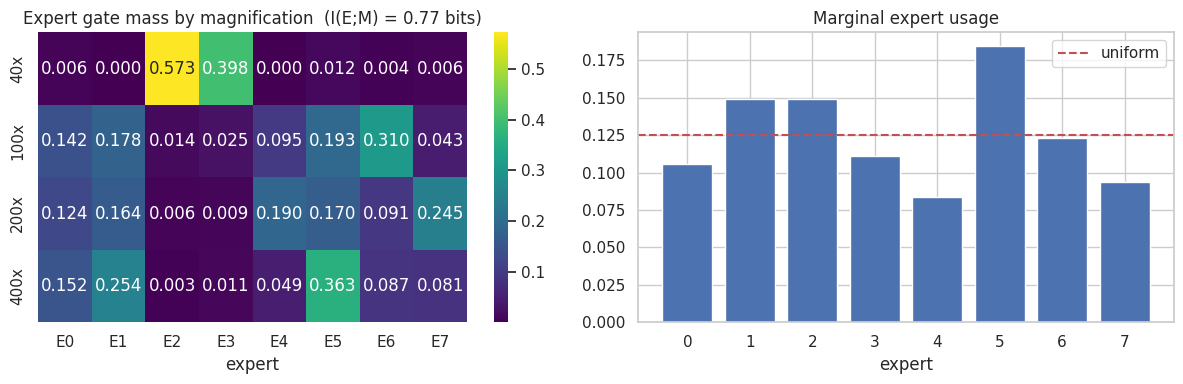

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(usage, annot=True, fmt=".3f", cmap="viridis",
            yticklabels=[f"{m}x" for m in bc.MAGS],
            xticklabels=[f"E{i}" for i in range(cfg.n_experts)], ax=ax[0])
ax[0].set_title(f"Expert gate mass by magnification  (I(E;M) = {mi:.2f} bits)")
ax[0].set_xlabel("expert")

ax[1].bar(range(cfg.n_experts), usage.mean(0))
ax[1].axhline(1.0 / cfg.n_experts, ls="--", c="r", label="uniform")
ax[1].set_title("Marginal expert usage")
ax[1].set_xlabel("expert")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG / "fig_expert_usage.png", dpi=150)
plt.show()

## Test 4 — does zooming actually help?

`step_prob[:, k]` is the prediction after seeing magnifications `0..k`, and
`utility[:, k]` is `|g_k * delta_k|`, how much that magnification moved the
state. If accuracy is flat across `k`, the extra magnifications are decoration.

In [8]:
step_prob = res["step_prob"]
util = res["utility"]
y = res["label"]
pid = res["patient_idx"]

rows = []
for k in range(step_prob.shape[1]):
    m = bc.evaluate(y, step_prob[:, k], pid)
    m["mags_seen"] = k + 1
    m["mean_utility"] = float(util[:, k].mean())
    rows.append(m)
zoom_curve = pd.DataFrame(rows).set_index("mags_seen")
display(zoom_curve.round(4))
zoom_curve.to_csv("/kaggle/working/test4_zoom_gain.csv")

lift = float(zoom_curve.loc[4, "auc"] - zoom_curve.loc[1, "auc"])
print(f"\nAUC lift from 40x alone to all four magnifications: {lift:+.4f}")
if lift < 0.01:
    print("VERDICT: higher magnifications add nothing measurable here. "
          "Report that honestly - it is a clinically relevant finding.")

,acc,f1_macro,prr,auc,mean_utility
mags_seen,,,,,
1,0.8980,0.8546,0.8982,0.9383,740.9610
2,0.9219,0.8919,0.9202,0.9741,455.4903
3,0.9284,0.9018,0.9253,0.9780,434.7463
4,0.9176,0.8859,0.9157,0.9786,506.4681



AUC lift from 40x alone to all four magnifications: +0.0403


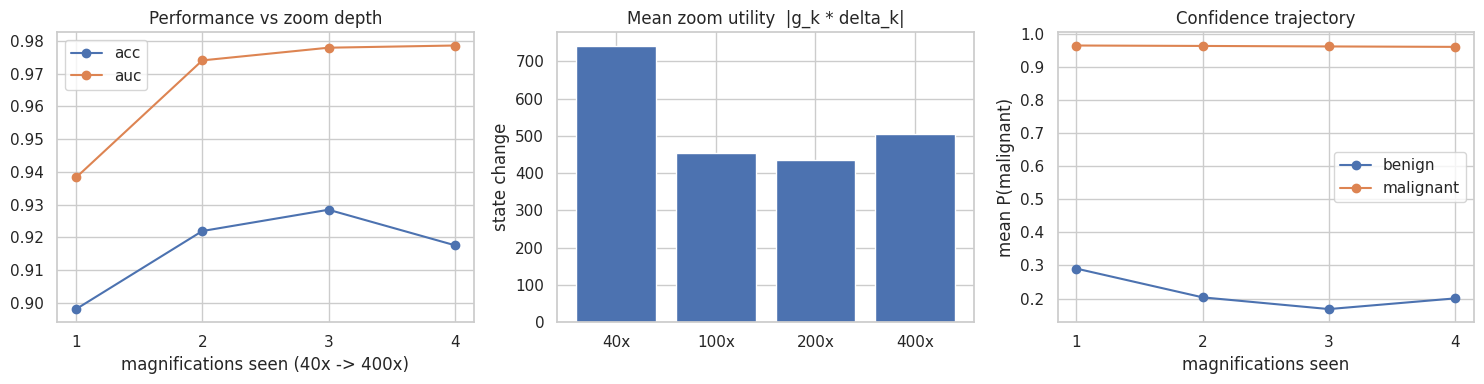

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
zoom_curve[["acc", "auc"]].plot(marker="o", ax=ax[0])
ax[0].set_xticks([1, 2, 3, 4])
ax[0].set_xlabel("magnifications seen (40x -> 400x)")
ax[0].set_title("Performance vs zoom depth")

ax[1].bar([f"{m}x" for m in bc.MAGS], util.mean(0))
ax[1].set_title("Mean zoom utility  |g_k * delta_k|")
ax[1].set_ylabel("state change")

for cls, name in [(0, "benign"), (1, "malignant")]:
    ax[2].plot(range(1, 5), step_prob[y == cls].mean(0), marker="o", label=name)
ax[2].set_xticks([1, 2, 3, 4])
ax[2].set_xlabel("magnifications seen")
ax[2].set_ylabel("mean P(malignant)")
ax[2].set_title("Confidence trajectory")
ax[2].legend()
plt.tight_layout()
plt.savefig(FIG / "fig_zoom_gain.png", dpi=150)
plt.show()

### Adaptive magnification budget

Stop zooming once the utility of the next step falls below a threshold. This
trades accuracy for acquisition cost, which is the clinically meaningful axis.

,acc,f1_macro,prr,auc,threshold,mean_mags_used
0,0.9176,0.8859,0.9157,0.9786,84.5591,4.0000
1,0.9154,0.8832,0.9129,0.9767,236.3388,3.5358
2,0.9067,0.8687,0.9053,0.9667,385.4814,2.9349
3,0.9024,0.8617,0.9019,0.9492,475.8536,1.9588
4,0.8959,0.8520,0.8954,0.9349,560.3624,1.3080
5,0.8959,0.8520,0.8954,0.9346,644.8454,1.1410


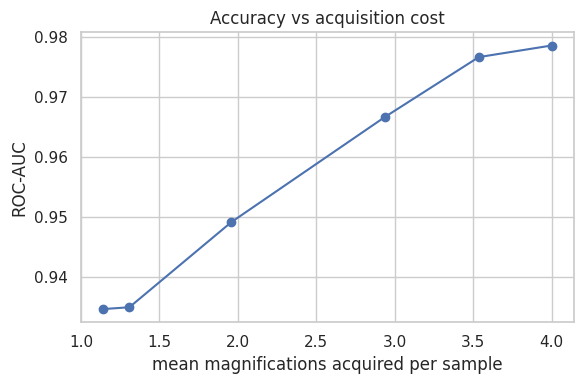

In [10]:
def early_exit_curve(step_prob, util, y, pid, thresholds):
    rows = []
    for t in thresholds:
        chosen = np.full(len(y), step_prob.shape[1] - 1)
        for i in range(len(y)):
            for k in range(step_prob.shape[1] - 1):
                if util[i, k + 1] < t:
                    chosen[i] = k
                    break
        probs = step_prob[np.arange(len(y)), chosen]
        m = bc.evaluate(y, probs, pid)
        m["threshold"] = t
        m["mean_mags_used"] = float(chosen.mean() + 1)
        rows.append(m)
    return pd.DataFrame(rows)


ths = np.quantile(util[:, 1:].ravel(), [0.0, 0.1, 0.25, 0.5, 0.75, 0.9])
ee = early_exit_curve(step_prob, util, y, pid, ths)
display(ee.round(4))

plt.figure(figsize=(6, 4))
plt.plot(ee["mean_mags_used"], ee["auc"], marker="o")
plt.xlabel("mean magnifications acquired per sample")
plt.ylabel("ROC-AUC")
plt.title("Accuracy vs acquisition cost")
plt.tight_layout()
plt.savefig(FIG / "fig_early_exit.png", dpi=150)
plt.show()

## Test 5 — random-label control

Shuffle labels within the training fold and retrain briefly. Test performance
must collapse to chance. Anything above chance means information is leaking
through the fold construction.

In [11]:
RUN_RANDOM_LABEL = False   # a few minutes of GPU time

if RUN_RANDOM_LABEL:
    from dataclasses import replace

    shuffled = samples.copy()
    rng = np.random.default_rng(SEED)
    tr_idx = folds[FOLD]["train"]
    perm = rng.permutation(tr_idx)
    shuffled.loc[shuffled.index[tr_idx], "label"] = samples["label"].values[perm]

    ctrl_cfg = replace(cfg, pretrained=True)
    ctrl = zm.ZoomMoE(ctrl_cfg).to(DEVICE)
    tr_loader = DataLoader(
        bc.make_image_dataset(shuffled.iloc[tr_idx], train=True, img_size=cfg.img_size),
        batch_size=8, shuffle=True, num_workers=2, drop_last=True,
    )
    opt = torch.optim.AdamW([p for p in ctrl.parameters() if p.requires_grad], lr=3e-4)
    ctrl.train()
    for ep in range(3):
        for batch in tr_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            out = ctrl(batch["images"], batch["mask"])
            total, _ = zm.compute_losses(out, batch, ctrl_cfg)
            opt.zero_grad(set_to_none=True)
            total.backward()
            opt.step()
    ctrl_res = zm.collect(ctrl, test_loader, DEVICE)
    print("random-label control:", {k: round(v, 4)
          for k, v in bc.evaluate(ctrl_res["label"], ctrl_res["prob"], ctrl_res["patient_idx"]).items()})
    print("AUC should sit near 0.50. Anything above ~0.60 means the folds leak.")
    del ctrl
    torch.cuda.empty_cache()

## Figures for the report

### t-SNE, before and after

The "before" panel uses the frozen VGG16 features from notebook 01, so it is
directly comparable to Figure 3 of the current progress report. The "after"
panel uses the ZoomMoE fused state on **held-out** samples, which the original
figure did not.

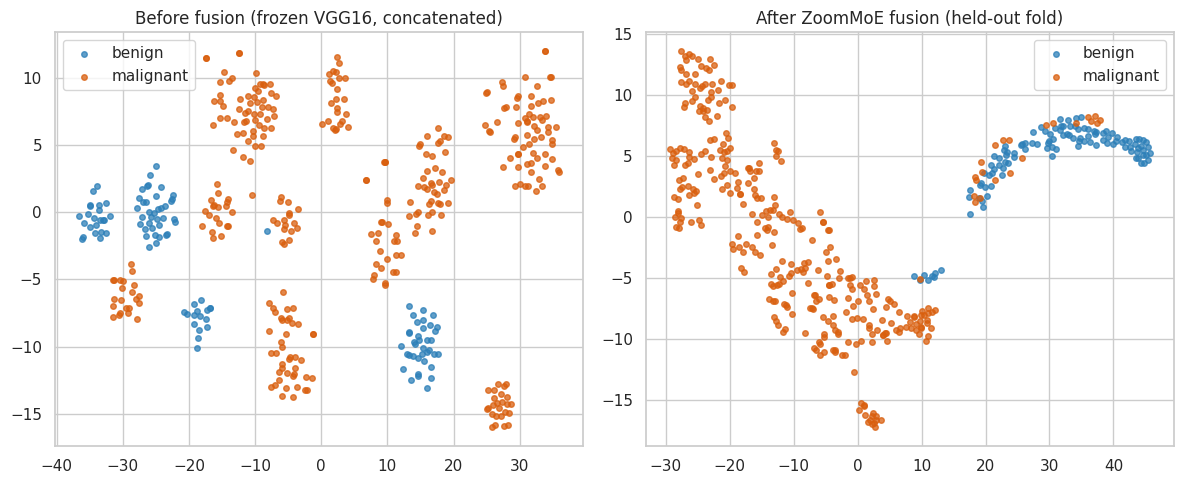

In [12]:
z = np.load(OUT / "vgg16_features.npz")
feat_cache = {k: z[k] for k in z.files}

test_samples = samples.iloc[test_idx].reset_index(drop=True)
before = []
for i, row in test_samples.iterrows():
    parts = []
    for m in bc.MAGS:
        c = row[f"cand{m}"]
        parts.append(feat_cache[c[i % len(c)]] if c else np.zeros(512, dtype=np.float32))
    before.append(np.concatenate(parts))
before = np.stack(before)

def tsne2d(x, seed=SEED):
    perp = min(30, max(5, len(x) // 4))
    return TSNE(n_components=2, perplexity=perp, init="pca", random_state=seed).fit_transform(x)


before_2d = tsne2d(before)
after_2d = tsne2d(res["state"])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, xy, title in [(ax[0], before_2d, "Before fusion (frozen VGG16, concatenated)"),
                     (ax[1], after_2d, "After ZoomMoE fusion (held-out fold)")]:
    for cls, name, c in [(0, "benign", "#2c7fb8"), (1, "malignant", "#d95f0e")]:
        sel = res["label"] == cls
        a.scatter(xy[sel, 0], xy[sel, 1], s=16, alpha=0.75, label=name, c=c)
    a.set_title(title)
    a.legend()
plt.tight_layout()
plt.savefig(FIG / "fig_tsne_before_after.png", dpi=150)
plt.show()

### The zoom manifold

The ordinal regulariser should make the scale-specific subspace an ordered
trajectory rather than four unstructured blobs. If the four colours are
intermixed, `w_ordinal` is too low or the loss is not doing its job.

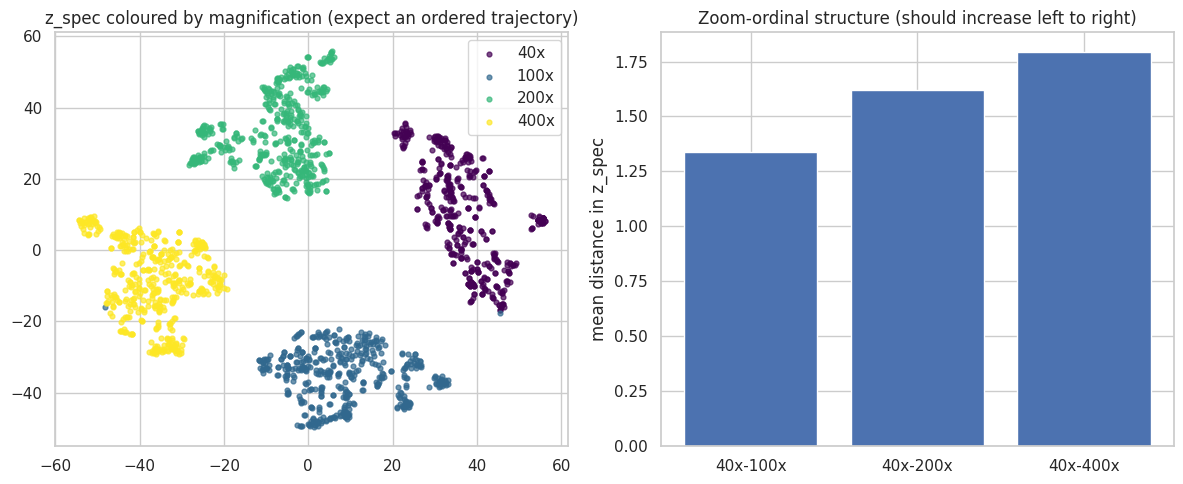

ordinal constraint satisfied on held-out data: True [1.3371044397354126, 1.6204107999801636, 1.7933540344238281]


In [13]:
z_spec = res["z_spec"]
valid = res["mask"]
flat = np.concatenate([z_spec[:, m][valid[:, m]] for m in range(4)])
mag_lab = np.concatenate([np.full(int(valid[:, m].sum()), m) for m in range(4)])
spec_2d = tsne2d(flat)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
palette = ["#440154", "#31688e", "#35b779", "#fde725"]
for m in range(4):
    sel = mag_lab == m
    ax[0].scatter(spec_2d[sel, 0], spec_2d[sel, 1], s=12, alpha=0.7,
                  c=palette[m], label=f"{bc.MAGS[m]}x")
ax[0].set_title("z_spec coloured by magnification (expect an ordered trajectory)")
ax[0].legend()

# distance from the 40x anchor should grow monotonically with zoom
d = np.stack([
    np.linalg.norm(z_spec[:, m] - z_spec[:, 0], axis=-1)
    for m in range(1, 4)
], axis=1)
ok = valid[:, 0][:, None] & valid[:, 1:]
means = [float(d[:, k][ok[:, k]].mean()) for k in range(3)]
ax[1].bar([f"40x-{bc.MAGS[k + 1]}x" for k in range(3)], means)
ax[1].set_ylabel("mean distance in z_spec")
ax[1].set_title("Zoom-ordinal structure (should increase left to right)")
plt.tight_layout()
plt.savefig(FIG / "fig_zoom_manifold.png", dpi=150)
plt.show()

monotone = all(means[k] < means[k + 1] for k in range(len(means) - 1))
print("ordinal constraint satisfied on held-out data:", monotone, means)

### Where the model looks when it zooms

Attention from the PZR queries back onto the spatial tokens of each
magnification. These are 7x7 maps upsampled over the input, and they are
soft evidence selection rather than registered localisation — BreaKHis
magnifications are not the same field of view.

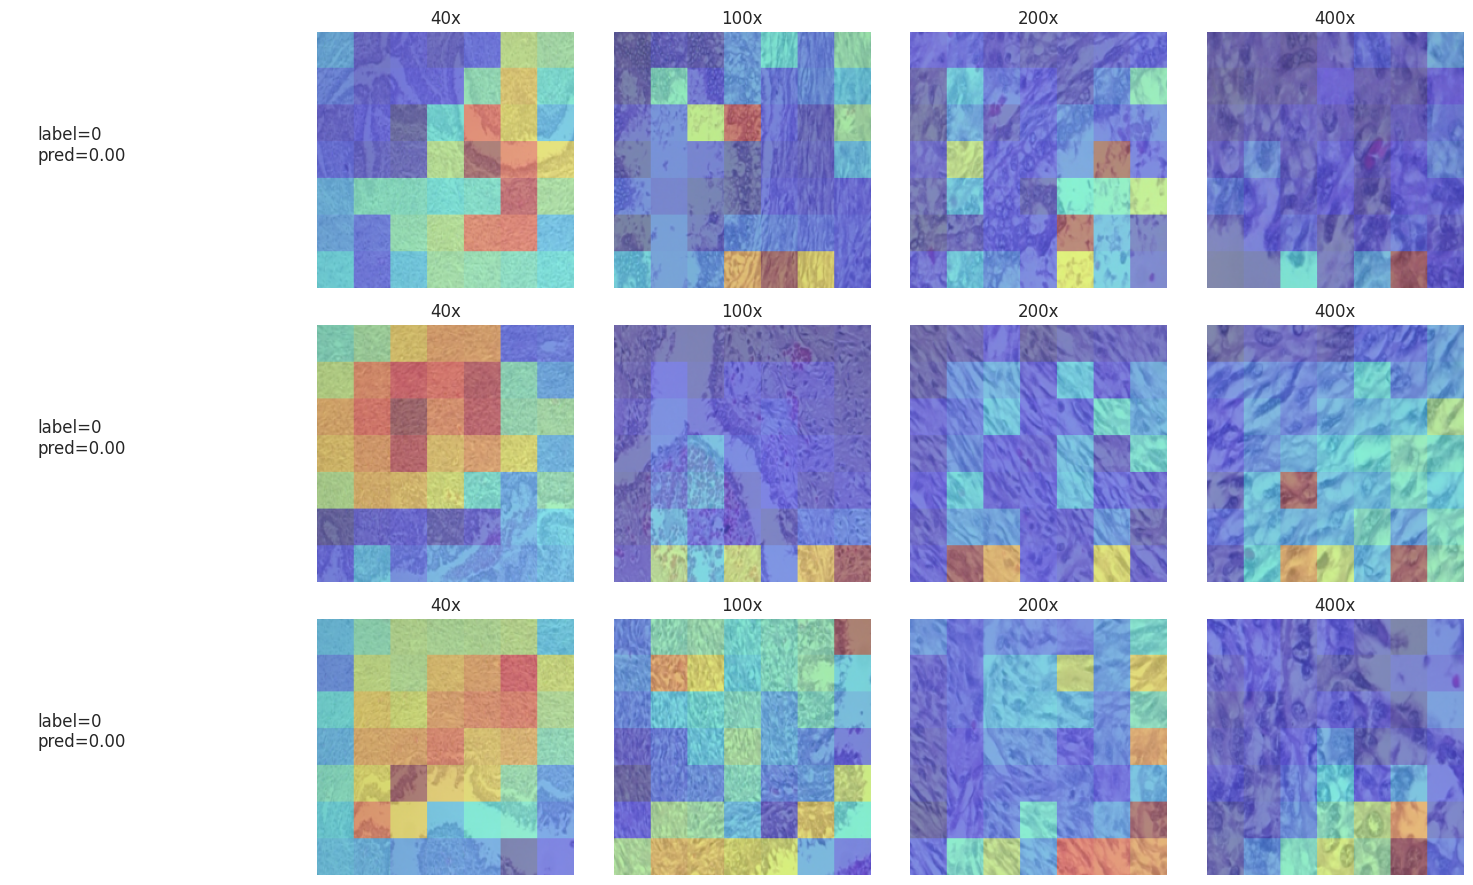

In [14]:
@torch.no_grad()
def attention_figure(model, dataset, n=3):
    grid = int(cfg.img_size // 32)
    fig, axes = plt.subplots(n, 5, figsize=(15, 3 * n))
    for r in range(n):
        item = dataset[r]
        out = model(item["images"].unsqueeze(0).to(DEVICE),
                    item["mask"].unsqueeze(0).to(DEVICE), need_attn=True)
        prob = float(torch.sigmoid(out["logit"]))
        axes[r, 0].text(0.1, 0.5, f"label={int(item['label'])}\npred={prob:.2f}", fontsize=12)
        axes[r, 0].axis("off")
        for m in range(4):
            a = out["attn"][m][0].mean(0).reshape(grid, grid).cpu().numpy()
            img = item["images"][m].permute(1, 2, 0).numpy()
            img = np.clip(img * np.array(bc.IMAGENET_STD) + np.array(bc.IMAGENET_MEAN), 0, 1)
            axes[r, m + 1].imshow(img)
            axes[r, m + 1].imshow(
                np.kron(a, np.ones((cfg.img_size // grid, cfg.img_size // grid))),
                cmap="jet", alpha=0.4,
            )
            axes[r, m + 1].set_title(f"{bc.MAGS[m]}x")
            axes[r, m + 1].axis("off")
    plt.tight_layout()
    plt.savefig(FIG / "fig_zoom_attention.png", dpi=150)
    plt.show()


ds = bc.make_image_dataset(samples.iloc[test_idx], train=False, img_size=cfg.img_size)
attention_figure(model, ds, n=3)

## Assembling the results table

In [15]:
summary_rows = {}
try:
    base = pd.read_csv(OUT / "baseline_results_honest.csv", index_col=0)
    print("baselines (notebook 01):")
    display(base)
except FileNotFoundError:
    base = None

try:
    zres = pd.read_csv(OUT / "zoommoe_results.csv")
    zres = zres.drop(columns=[c for c in ("fold",) if c in zres.columns])
    summary_rows["ZoomMoE (full)"] = bc.summarise_folds(zres.to_dict("records"))["mean"]
except FileNotFoundError:
    summary_rows["ZoomMoE (fold %d only)" % FOLD] = pd.Series(base_metrics)

final = pd.DataFrame(summary_rows).T
display(final.round(4))

verdicts = pd.DataFrame([
    {"test": "order permutation", "statistic": f"AUC gap {gap:+.4f}",
     "passes": gap >= 0.01},
    {"test": "patient probe (state)", "statistic": f"{probe_state['ratio']:.1f}x chance",
     "passes": probe_state["ratio"] < 5},
    {"test": "expert specialisation", "statistic": f"I(E;M) {mi:.3f} bits",
     "passes": mi >= 0.05},
    {"test": "zoom gain", "statistic": f"AUC lift {lift:+.4f}",
     "passes": lift >= 0.01},
    {"test": "ordinal structure", "statistic": str([round(m, 3) for m in means]),
     "passes": monotone},
]).set_index("test")
display(verdicts)
verdicts.to_csv("/kaggle/working/falsification_verdicts.csv")

print("\nA failed row is not a bug to hide. Each one narrows what can honestly "
      "be claimed, and a negative result on the zoom premise is itself worth "
      "reporting given how much multi-scale histopathology work assumes it.")

baselines (notebook 01):


,Image Acc,Patient RR,Macro-F1,ROC-AUC
single_40x,0.8083 ± 0.0752,0.8080 ± 0.0740,0.7562 ± 0.0670,0.8520 ± 0.1023
single_400x,0.8418 ± 0.0646,0.8410 ± 0.0559,0.8018 ± 0.0734,0.8987 ± 0.0664
concat_4scale,0.8639 ± 0.0940,0.8573 ± 0.0823,0.8154 ± 0.1289,0.9211 ± 0.0656
conditional_fusion,0.7161 ± 0.2801,0.7082 ± 0.2805,0.6969 ± 0.2704,0.9017 ± 0.0746


,acc,f1_macro,prr,auc
ZoomMoE (fold 0 only),0.9197,0.8892,0.9174,0.9811


,statistic,passes
test,,
order permutation,AUC gap +0.0205,True
patient probe (state),11.9x chance,False
expert specialisation,I(E;M) 0.774 bits,True
zoom gain,AUC lift +0.0403,True
ordinal structure,"[1.337, 1.62, 1.793]",True



A failed row is not a bug to hide. Each one narrows what can honestly be claimed, and a negative result on the zoom premise is itself worth reporting given how much multi-scale histopathology work assumes it.
